# Pakistan Toshakhana Files: gift analysis, 2002-2022

Source: [Kaggle: zusmani/pakistan-toshakhana-files](https://www.kaggle.com/datasets/zusmani/pakistan-toshakhana-files), file `Refined_TK_data ver 2.csv` (stored here as `data/toshakhana_refined_raw.csv`).

The Toshakhana is the government department that holds gifts received by officials from foreign dignitaries. Recipients may keep a gift by paying a share of its assessed value (the *retention cost*).

All amounts are nominal PKR, not adjusted for inflation.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', 90)
pd.set_option('display.float_format', lambda v: f'{v:,.0f}' if abs(v) >= 100 else f'{v:,.2f}')
plt.rcParams.update({'figure.figsize': (10, 4.5), 'axes.spines.top': False, 'axes.spines.right': False})
M = 1e6  # PKR million

## 1. Load

In [2]:
raw = pd.read_csv('data/toshakhana_refined_raw.csv')
print(raw.shape)
raw.head()

(4214, 9)


,Detail of Gifts,Item Category,Name of Recipient,Affiliation,Date,Assessed Value,Retention Cost,Retained,Remarks
0,Two small silver\nBowls,Decoration Pieces,"Mr. Abdul Sattar, Minister for Foreign\nAffairs",Gen. Musharrafarraf,1/8/2002,"5,000",0.00,Yes,Yes
1,One Pilot Pen with\nink,Pen,"Mr. Abdul Sattar, Minister for Foreign\nAffairs",Gen. Musharraf,1/8/2002,"3,500",0.00,Yes,Yes
2,One silver vase,Decoration Pieces,"Mr. Shaukat Aziz, Minister for Finance",Gen. Musharraf,1/9/2002,"7,500",0.00,Yes,Yes
3,One (decoration)\nfolding Screen,Decoration Pieces,"Mr. Abdul Sattar, Minister for Foreign\nAffairs",Gen. Musharraf,1/15/2002,"2,200",0.00,Yes,Yes
4,One Decoration\nPiece,Decoration Pieces,"Mr. Abdul Sattar, Minister for Foreign\nAffairs",Gen. Musharraf,1/22/2002,"2,000",0.00,Yes,Yes


In [3]:
pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(),
              'missing_%': (raw.isna().mean()*100).round(1), 'unique': raw.nunique()})

,dtype,missing,missing_%,unique
Detail of Gifts,str,6,0.10,3248
Item Category,str,1876,44.50,22
Name of Recipient,str,0,0.00,2047
Affiliation,str,1007,23.90,12
Date,str,3,0.10,1450
Assessed Value,float64,1,0.00,571
Retention Cost,float64,9,0.20,421
Retained,str,11,0.30,72
Remarks,str,11,0.30,229


## 2. Clean

- collapse whitespace / line breaks left over from the PDF extraction
- drop exact duplicate rows
- parse dates
- merge the three spellings of the Musharraf-era label (`Gen. Musharraf`, `Gen Mus`, `Gen. Musharrafarraf`)
- normalise the free-text `Retained` column into a `Status`
- fill the missing `Item Category` (44% blank) with keyword rules → `Category`
- map the ~1,900 recipient spellings to a canonical `Person` for the main office holders (gifts to spouses/children are counted under the office holder's household)

In [4]:
df = raw.copy()
for c in df.columns[df.dtypes.astype(str).isin(['object', 'str', 'string'])]:
    df[c] = df[c].map(lambda s: re.sub(r'\s+', ' ', s).strip() if isinstance(s, str) else s)

before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print('duplicates dropped:', before - len(df))

df = df.rename(columns={'Detail of Gifts': 'Gift', 'Name of Recipient': 'Recipient',
                        'Assessed Value': 'Assessed', 'Retention Cost': 'Paid'})
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df['Year'] = df['Date'].dt.year.astype('Int64')

df['Affiliation'] = (df['Affiliation']
                     .replace({'Gen Mus': 'Musharraf govt', 'Gen. Musharraf': 'Musharraf govt',
                               'Gen. Musharrafarraf': 'Musharraf govt'})
                     .fillna('Unlabelled'))

def status(s):
    if not isinstance(s, str): return 'Unknown'
    t = s.lower()
    if 'auction' in t: return 'Auctioned'
    if 'display' in t: return 'Displayed (state property)'
    if 'not deposited' in t: return 'Declared, not deposited'
    if t == 'no' or 'deposited' in t or 'transferred' in t: return 'Deposited / not retained'
    if t == 'yes' or 'retain' in t: return 'Retained'
    return 'Other / unclear'
df['Status'] = df['Retained'].map(status)

CAT_RULES = [
    ('Vehicle', r'bmw 760|lexus (?:lx )?470|toyota vxr|mercedes benz car|proton car|tractor'),
    ('Watch', r'watch|rolex|clock'),
    ('Jewellery/Accessories', r'jewel|necklace|bracelet|ring\b|cufflink|tasbih|gold|diamond|pearl|brooch|locket'),
    ('Carpet', r'carpet|rug\b'),
    ('Weapons', r'dagger|sword|pistol|rifle|gun\b|knife|kalashnikov'),
    ('Phone', r'mobile|phone'),
    ('Tech', r'laptop|ipad|camera|computer|music player|tablet|dvd|radio'),
    ('Pen', r'\bpen\b|ballpen|ball point'),
    ('Clothes', r'shawl|gown|saree|scarf|tie\b|suit|cloth piece|cap\b|robe|dress|shirt|jacket|abaya'),
    ('Crockery', r'tea set|coffee set|dinner set|cutlery|crockery|\bcup|plate|bowl|tray|glass set|jug'),
    ('Food', r'sweet|dates|honey|chocolate|tea\b|coffee\b|fruit|food|saffron|nuts'),
    ('Cigar/Cigarettes', r'cigar'),
    ('Books/Media', r'book|album|\bcd\b|brochure|quran'),
    ('Bags', r'\bbag|briefcase|wallet|purse|suitcase'),
    ('Decoration Pieces', r'vase|decoration|shield|painting|frame|model|statue|box|souvenir|plaque|wall hanging|'
                          r'sculpture|lamp|candle|crystal|portrait|medal|coin|replica|picture|panel|ewer|handicraft'),
]
def infer_cat(row):
    c = row['Item Category']
    if isinstance(c, str):
        c = c.split(',')[0].strip()
        return {'Technology': 'Tech', 'Clock': 'Watch', 'Bag': 'Bags', 'Jewellery': 'Jewellery/Accessories'}.get(c, c)
    g = str(row['Gift']).lower()
    for name, pat in CAT_RULES:
        if re.search(pat, g): return name
    return 'Other'
df['Category'] = df.apply(infer_cat, axis=1)
# vehicles are hidden in the blank-category rows; make sure they get their own bucket
df.loc[df['Gift'].str.contains(r'bmw 760|lexus (?:lx )?470|toyota vxr|mercedes benz car|proton car|tractor', case=False, na=False), 'Category'] = 'Vehicle'

PEOPLE = [  # order matters
    ('Shaukat Aziz', r'shaukat\s+aziz'), ('Asif Ali Zardari', r'zardari(?!.*bilawal)'),
    ('Imran Khan', r'imran\s+khan'), ('Arif Alvi', r'arif\s+alvi'),
    ('Pervez Musharraf', r'mush?ar+a?f'), ('Shehbaz Sharif', r'she?h?baz\s+sharif'),
    ('Nawaz Sharif', r'nawaz\s+sharif'), ('Mamnoon Hussain', r'mamnoon'),
    ('Zafarullah Jamali', r'jamali'), ('Shahid Khaqan Abbasi', r'khaqan\s+abbasi'),
    ('Yousaf Raza Gillani', r'gil+ani'), ('Khurshid Kasuri', r'kasuri'),
    ('Raja Pervez Ashraf', r'pervez\s+ashraf'), ('Shah Mehmood Qureshi', r'mehmood\s+(hussain\s+)?qureshi'),
    ('Sartaj Aziz', r'sartaj'), ('Raza Rabbani', r'rabbani'), ('Ishaq Dar', r'ishaq\s+dar'),
    ('Khawaja Asif', r'khawaja\s+(muhammad\s+)?asif'),
]
def person(r):
    t = r.lower()
    if 'bilawal' in t: return 'Bilawal Bhutto Zardari'
    for name, pat in PEOPLE:
        if re.search(pat, t): return name
    return 'Other'
df['Person'] = df['Recipient'].map(person)
df['Family'] = df['Recipient'].str.contains(r'wife|begum|first lady|son of|daughter|spouse', case=False)

print(df.shape)
df[['Gift', 'Category', 'Recipient', 'Person', 'Affiliation', 'Date', 'Assessed', 'Paid', 'Status']].head()

duplicates dropped: 16


(4198, 14)


,Gift,Category,Recipient,Person,Affiliation,Date,Assessed,Paid,Status
0,Two small silver Bowls,Decoration Pieces,"Mr. Abdul Sattar, Minister for Foreign Affairs",Other,Musharraf govt,2002-01-08,"5,000",0.00,Retained
1,One Pilot Pen with ink,Pen,"Mr. Abdul Sattar, Minister for Foreign Affairs",Other,Musharraf govt,2002-01-08,"3,500",0.00,Retained
2,One silver vase,Decoration Pieces,"Mr. Shaukat Aziz, Minister for Finance",Shaukat Aziz,Musharraf govt,2002-01-09,"7,500",0.00,Retained
3,One (decoration) folding Screen,Decoration Pieces,"Mr. Abdul Sattar, Minister for Foreign Affairs",Other,Musharraf govt,2002-01-15,"2,200",0.00,Retained
4,One Decoration Piece,Decoration Pieces,"Mr. Abdul Sattar, Minister for Foreign Affairs",Other,Musharraf govt,2002-01-22,"2,000",0.00,Retained


## 3. Headline numbers

In [5]:
kept = df['Status'].eq('Retained')
free = kept & (df['Paid'].fillna(0) == 0)
head = pd.Series({
    'Gift records': len(df),
    'Date range': f"{df['Date'].min():%d %b %Y} – {df['Date'].max():%d %b %Y}",
    'Distinct recipient strings': df['Recipient'].nunique(),
    'Total assessed value (PKR m)': round(df['Assessed'].sum()/M, 1),
    'Total paid to retain (PKR m)': round(df['Paid'].sum()/M, 1),
    'Paid as % of assessed': round(df['Paid'].sum()/df['Assessed'].sum()*100, 1),
    'Records retained': f"{kept.sum()} ({kept.mean()*100:.1f}%)",
    'Retained for free (paid = 0)': f"{free.sum()} ({free.sum()/kept.sum()*100:.1f}% of retained)",
    'Assessed value of free-retained gifts (PKR m)': round(df.loc[free, 'Assessed'].sum()/M, 1),
    'Records with assessed value 0': int((df['Assessed'] == 0).sum()),
    'Median assessed value (PKR)': df['Assessed'].median(),
    'Mean assessed value (PKR)': round(df['Assessed'].mean()),
})
head.to_frame('value')

,value
Gift records,4198
Date range,08 Jan 2002 – 24 Oct 2022
Distinct recipient strings,1875
Total assessed value (PKR m),"1,353"
Total paid to retain (PKR m),204
Paid as % of assessed,15.10
Records retained,3726 (88.8%)
Retained for free (paid = 0),2367 (63.5% of retained)
Assessed value of free-retained gifts (PKR m),37.60
Records with assessed value 0,589


In [6]:
df[['Assessed', 'Paid']].describe(percentiles=[.25, .5, .75, .9, .99]).T

,count,mean,std,min,25%,50%,75%,90%,99%,max
Assessed,"4,197","322,272","3,901,437",0.00,"1,800","8,000","40,000","132,420","4,002,000","140,000,000"
Paid,"4,189","48,698","619,627",0.00,0.00,0.00,"2,269","16,000","647,251","20,178,000"


### Value is extremely concentrated
A handful of gifts account for most of the money.

,top N gifts,share of total assessed value %
0,1,10.40
1,10,49.00
2,20,61.80
3,50,74.00
4,100,83.10
5,41,71.50
6,419,94.70


,gifts,assessed_m,gifts_%,value_%
Assessed,,,,
0,589,0.00,14.00,0.00
1–10k,1798,7.71,42.80,0.60
10k–30k,619,12.56,14.70,0.90
30k–100k,681,40.86,16.20,3.00
100k–1m,382,134,9.10,9.90
1m–10m,106,300,2.50,22.20
10m+,22,858,0.50,63.40


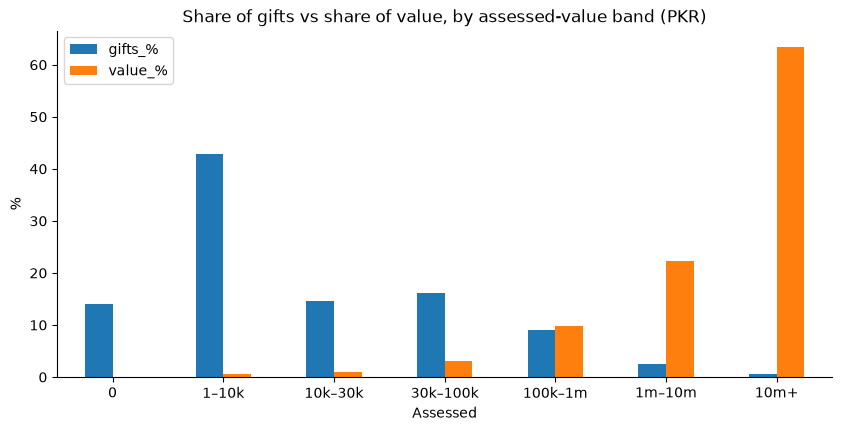

In [7]:
s = df['Assessed'].fillna(0).sort_values(ascending=False)
tot = s.sum()
conc = pd.DataFrame({'top N gifts': [1, 10, 20, 50, 100, int(len(s)*0.01), int(len(s)*0.10)]})
conc['share of total assessed value %'] = [round(s.head(n).sum()/tot*100, 1) for n in conc['top N gifts']]
display(conc)

bins = [-1, 0, 10_000, 30_000, 100_000, 1_000_000, 10_000_000, np.inf]
labels = ['0', '1–10k', '10k–30k', '30k–100k', '100k–1m', '1m–10m', '10m+']
b = pd.cut(df['Assessed'], bins=bins, labels=labels)
dist = df.groupby(b, observed=False).agg(gifts=('Gift', 'size'), assessed_m=('Assessed', lambda x: x.sum()/M))
dist['gifts_%'] = (dist['gifts']/dist['gifts'].sum()*100).round(1)
dist['value_%'] = (dist['assessed_m']/dist['assessed_m'].sum()*100).round(1)
display(dist)

ax = dist[['gifts_%', 'value_%']].plot.bar(rot=0, title='Share of gifts vs share of value, by assessed-value band (PKR)')
ax.set_ylabel('%'); plt.show()

## 4. Over time

,gifts,assessed_m,paid_m,median_assessed,paid_%
Year,,,,,
2002,252,3.16,0.28,"1,800",8.80
2003,286,12.76,1.44,"6,500",11.30
2004,346,14.02,1.73,"5,500",12.30
2005,470,15.80,1.70,"3,500",10.80
2006,371,22.50,2.33,"4,000",10.40
2007,353,27.83,1.45,"4,000",5.20
2008,114,7.14,0.92,"6,000",12.90
2009,141,143,20.93,"7,500",14.60
2010,136,1.85,0.17,"2,500",9.00


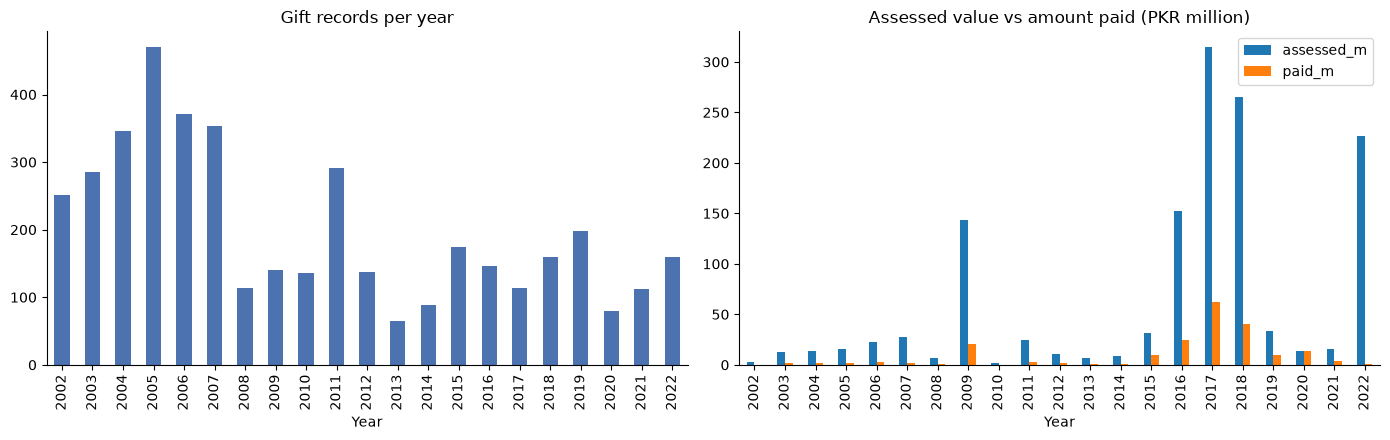

In [8]:
yr = df.groupby('Year').agg(gifts=('Gift', 'size'), assessed_m=('Assessed', lambda x: x.sum()/M),
                            paid_m=('Paid', lambda x: x.sum()/M), median_assessed=('Assessed', 'median'))
yr['paid_%'] = (yr['paid_m']/yr['assessed_m']*100).round(1)
display(yr)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
yr['gifts'].plot.bar(ax=ax[0], title='Gift records per year', color='#4C72B0')
yr[['assessed_m', 'paid_m']].plot.bar(ax=ax[1], title='Assessed value vs amount paid (PKR million)')
plt.tight_layout(); plt.show()

## 5. By affiliation
`Affiliation` is the dataset author's label, and 24% of rows are unlabelled, so party totals are indicative only.

,gifts,assessed_m,paid_m,median_assessed,max_assessed_m,paid_%,avg_assessed
Affiliation,,,,,,,
PMLN,256,425,53.21,"22,000",140,12.50,"1,661,220"
Unlabelled,1006,403,57.50,"9,000",99.98,14.30,"400,990"
PPP,246,175,22.14,"5,000",108,12.60,"712,184"
PTI,261,155,41.81,"25,640",101,27.10,"592,188"
Military,732,82.48,14.70,"10,900",6.43,17.80,"112,682"
Bureaucracy,299,47.86,6.78,"8,000",4.95,14.20,"160,080"
Musharraf govt,1147,39.96,3.85,"3,000",7.53,9.60,"34,840"
Police,119,16.32,3.02,"35,000",2.90,18.50,"137,184"
Media,121,6.29,0.87,"35,000",0.59,13.80,"51,960"


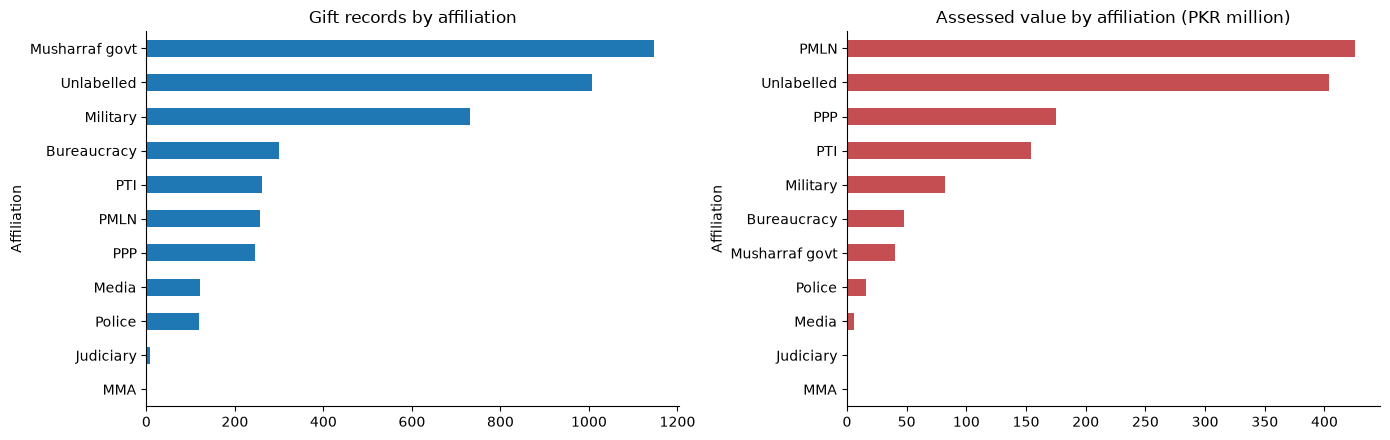

In [9]:
def summarise(g):
    out = g.agg(gifts=('Gift', 'size'), assessed_m=('Assessed', lambda x: x.sum()/M),
                paid_m=('Paid', lambda x: x.sum()/M), median_assessed=('Assessed', 'median'),
                max_assessed_m=('Assessed', lambda x: x.max()/M))
    out['paid_%'] = (out['paid_m']/out['assessed_m']*100).round(1)
    out['avg_assessed'] = (out['assessed_m']*M/out['gifts']).round(0)
    return out.sort_values('assessed_m', ascending=False)

aff = summarise(df.groupby('Affiliation'))
display(aff)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
aff['gifts'].sort_values().plot.barh(ax=ax[0], title='Gift records by affiliation')
aff['assessed_m'].sort_values().plot.barh(ax=ax[1], title='Assessed value by affiliation (PKR million)', color='#C44E52')
plt.tight_layout(); plt.show()

## 6. By person (household)
Includes gifts recorded against spouses and children of the office holder.

,gifts,assessed_m,paid_m,median_assessed,max_assessed_m,paid_%,avg_assessed,of_which_family_m
Person,,,,,,,,
Shahid Khaqan Abbasi,32,233,46.54,"250,000",99.98,20.00,"7,285,203",123
Shehbaz Sharif,66,161,0.46,"25,000",140,0.30,"2,444,349",0.00
Asif Ali Zardari,170,145,21.31,"3,000",108,14.60,"855,852",0.00
Nawaz Sharif,58,136,25.84,"12,500",54.33,18.90,"2,351,695",56.50
Imran Khan,109,124,34.39,"31,000",101,27.80,"1,135,483",3.40
Khawaja Asif,10,67.82,11.33,"227,500",44.40,16.70,"6,781,513",0.00
Pervez Musharraf,144,33.69,2.83,"5,750",14.88,8.40,"233,927",19.40
Shaukat Aziz,849,31.19,2.85,"3,000",7.53,9.10,"36,733",0.60
Arif Alvi,118,27.20,2.01,"12,000",19.22,7.40,"230,550",1.00


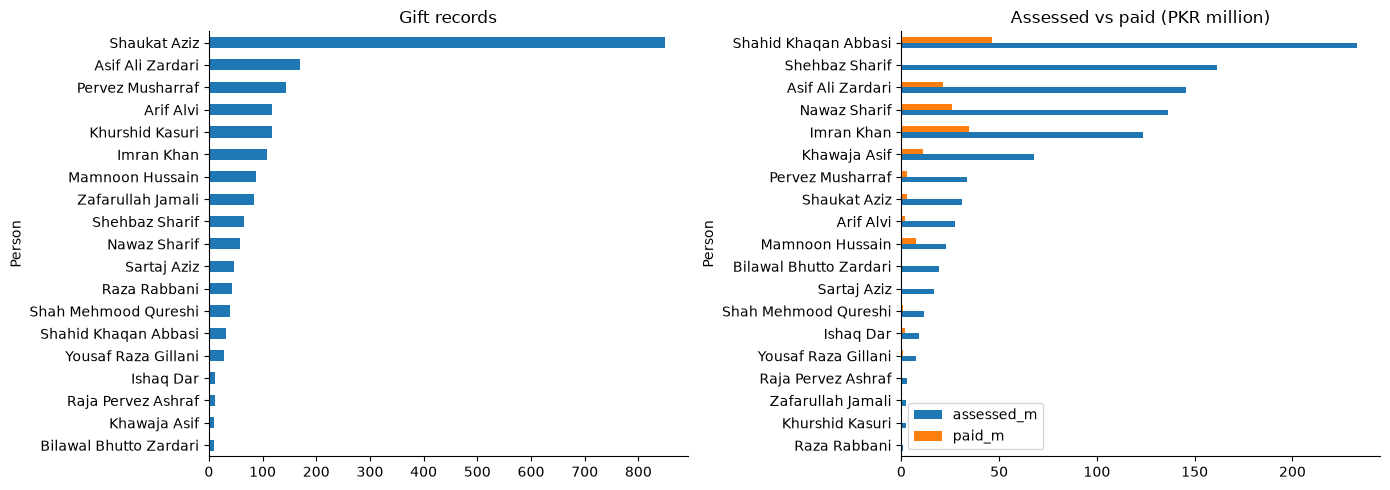

In [10]:
per = summarise(df[df['Person'] != 'Other'].groupby('Person'))
fam = df[df['Family']].groupby('Person')['Assessed'].sum()/M
per['of_which_family_m'] = fam.reindex(per.index).fillna(0).round(1)
display(per)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
per['gifts'].sort_values().plot.barh(ax=ax[0], title='Gift records')
per[['assessed_m', 'paid_m']].sort_values('assessed_m').plot.barh(ax=ax[1], title='Assessed vs paid (PKR million)')
plt.tight_layout(); plt.show()

## 7. By item category

,gifts,assessed_m,paid_m,median_assessed,max_assessed_m,paid_%,avg_assessed
Category,,,,,,,
Watch,1163,905,123,"60,000",140,13.60,"778,024"
Jewellery/Accessories,259,256,53.94,"11,500",99.98,21.10,"988,028"
Vehicle,10,139,20.91,0.00,108,15.00,"13,942,399"
Decoration Pieces,1074,15.80,1.51,"3,500",2.71,9.60,"14,715"
Carpet,250,11.78,1.50,"17,750",1.12,12.70,"47,116"
Other,321,5.58,0.45,"2,500",0.60,8.10,"17,396"
Weapons,83,5.44,0.95,"18,875",0.80,17.40,"65,493"
Crockery,356,5.41,0.44,"4,500",0.98,8.10,"15,206"
Phone,57,2.29,0.24,"28,000",0.25,10.50,"40,135"


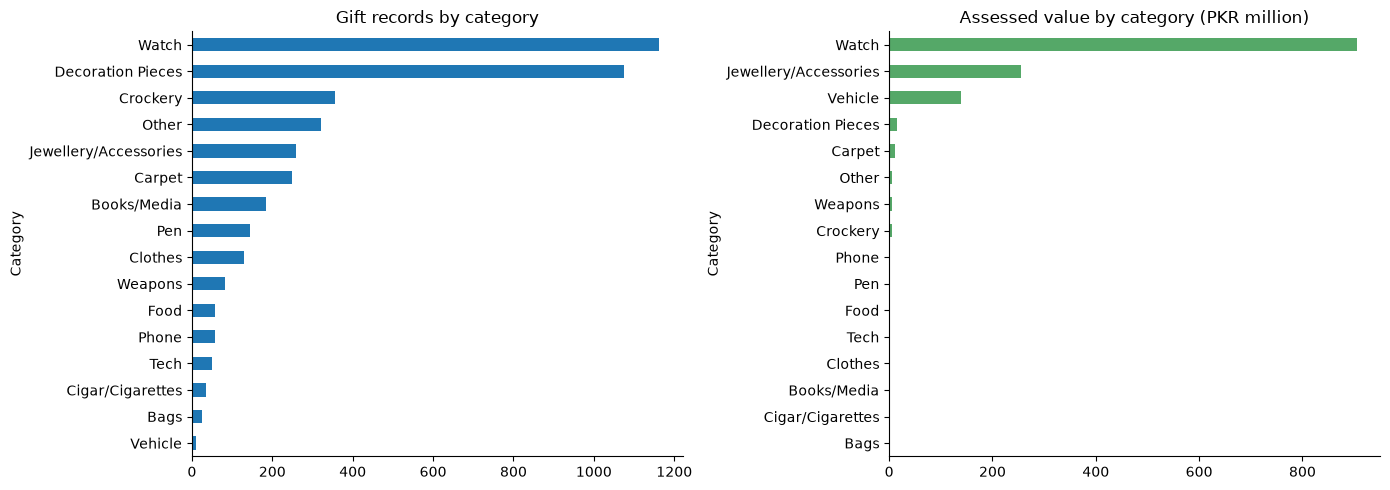

In [11]:
cat = summarise(df.groupby('Category'))
display(cat)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cat['gifts'].sort_values().plot.barh(ax=ax[0], title='Gift records by category')
cat['assessed_m'].sort_values().plot.barh(ax=ax[1], title='Assessed value by category (PKR million)', color='#55A868')
plt.tight_layout(); plt.show()

### Watch brands

In [12]:
BRANDS = ['Rolex', 'Chopard', 'Hublot', 'Graff', 'Cartier', 'Piaget', 'Omega', 'Concord', 'Chaumet', 'Hamilton',
          'Rado', 'Longines', 'Tissot', 'Seiko', 'Citizen', 'Bvlgari', 'Breitling', 'Patek', 'Corum', 'Franck Muller',
          'Officina', 'Mont Blanc', 'Montblanc', 'Raymond Weil', 'Tag Heuer', 'Harry Winston', 'Faberge', 'Dunhill',
          'Jaeger', 'Baume', 'Movado', 'Swatch', 'Casio', 'Gucci', 'Dior', 'Versace', 'Ebel', 'Zenith', 'Vacheron',
          'Audemars', 'Bovet', 'Boucheron', 'Christopher Claret', 'Carl F. Bucherer', 'Mouawad', 'Titus', 'Orient']
w = df[df['Category'] == 'Watch'].copy()
def brand(g):
    for b in BRANDS:
        if re.search(re.escape(b), g, flags=re.I): return 'Montblanc' if b == 'Mont Blanc' else b
    return 'Unidentified'
w['Brand'] = w['Gift'].map(brand)
wb = w.groupby('Brand').agg(records=('Gift', 'size'), assessed_m=('Assessed', lambda x: x.sum()/M),
                            median_assessed=('Assessed', 'median')).sort_values('records', ascending=False)
print(f"watch records: {len(w)}, assessed PKR {w['Assessed'].sum()/M:,.1f} m")
wb.head(20)

watch records: 1163, assessed PKR 904.8 m


,records,assessed_m,median_assessed
Brand,,,
Unidentified,490,95.30,"36,500"
Rolex,130,371,"865,910"
Concord,93,5.06,"40,000"
Bvlgari,75,29.99,"100,000"
Hamilton,43,2.38,"60,000"
Longines,42,3.39,"85,000"
Tissot,30,0.48,"14,000"
Chopard,24,59.18,"217,500"
Movado,23,1.66,"72,000"


## 8. What happened to the gifts

In [13]:
st = df.groupby('Status').agg(gifts=('Gift', 'size'), assessed_m=('Assessed', lambda x: x.sum()/M),
                              paid_m=('Paid', lambda x: x.sum()/M)).sort_values('gifts', ascending=False)
st['gifts_%'] = (st['gifts']/st['gifts'].sum()*100).round(1)
display(st)

r = df[df['Status'].eq('Retained') & (df['Assessed'] > 0)].copy()
r['ratio'] = r['Paid']/r['Assessed']
rb = pd.cut(r['ratio'], [-0.001, 0, 0.14, 0.16, 0.19, 0.21, 0.49, 0.51, 1, np.inf],
            labels=['free', '<15%', '~15%', '16–19%', '~20%', '21–49%', '~50%', '51–100%', '>100% (data issue)'])
rt = r.groupby(rb, observed=False).agg(gifts=('Gift', 'size'), assessed_m=('Assessed', lambda x: x.sum()/M))
rt['gifts_%'] = (rt['gifts']/rt['gifts'].sum()*100).round(1)
print('Retained gifts — price paid as a share of assessed value')
display(rt)

,gifts,assessed_m,paid_m,gifts_%
Status,,,,
Retained,3726,"1,010",202,88.80
Deposited / not retained,199,141,0.70,4.70
Auctioned,166,32.46,0.01,4.00
Displayed (state property),55,166,0.20,1.30
Other / unclear,35,2.63,0.64,0.80
Unknown,9,0.00,0.00,0.20
"Declared, not deposited",8,0.00,0.00,0.20


Retained gifts — price paid as a share of assessed value


,gifts,assessed_m,gifts_%
ratio,,,
free,1884,37.49,58.90
<15%,792,68.10,24.80
~15%,163,186,5.10
16–19%,140,16.51,4.40
~20%,126,646,3.90
21–49%,77,39.64,2.40
~50%,4,11.36,0.10
51–100%,4,0.69,0.10
>100% (data issue),6,5.07,0.20


Share of retained gifts kept for free, by year (%)


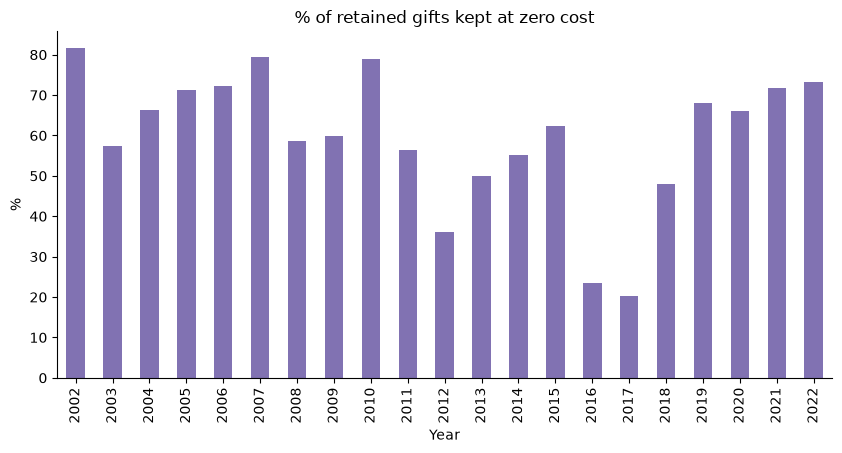

Year,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
free_%,81.70,57.30,66.20,71.30,72.30,79.50,58.70,59.80,78.90,56.50,...,50.00,55.20,62.30,23.50,20.20,48.10,68.10,66.00,71.80,73.30


In [14]:
print('Share of retained gifts kept for free, by year (%)')
fy = (df[df['Status'].eq('Retained')].assign(free=lambda d: d['Paid'].fillna(0).eq(0))
      .groupby('Year')['free'].mean()*100).round(1)
ax = fy.plot.bar(color='#8172B2', title='% of retained gifts kept at zero cost'); ax.set_ylabel('%'); plt.show()
fy.to_frame('free_%').T

## 9. Biggest individual gifts

In [15]:
cols = ['Date', 'Gift', 'Recipient', 'Affiliation', 'Assessed', 'Paid', 'Status']
top = df.nlargest(20, 'Assessed')[cols].copy()
top['Gift'] = top['Gift'].str.slice(0, 80)
top

,Date,Gift,Recipient,Affiliation,Assessed,Paid,Status
4098,2022-05-12,One wrist watch Rolex (Model No.326259TBR-Sr No.85C423E3),"Mian Muhammad Shehbaz Sharif, Prime Minister of Pakistan",PMLN,"140,000,000",0.00,Displayed (state property)
2195,2009-01-26,a. One BMW 760 Li (Security version) (model No.2008) b. One Toyota Lexus LX 470,"Mr. Asif Ali Zardari, President of Pakistan",PPP,"107,828,705","16,172,806",Retained
3585,2018-09-24,a) (One W/Watch (Graff No.AU750) 18k gold + Dimond b) (Pair of Cufflinks. c) One,"Prime Minister of Pakistan, Imran Khan",PTI,"100,920,000","20,178,000",Retained
3448,2017-10-17,"One jewelry set including one necklace, a pair of ear tops, one ring & one brace","Ms. Sameena Shahid, wife of Mr. Shahid Khaqan Abbasi, Prime Minister,",Unlabelled,"99,984,000","19,990,800",Retained
3234,2016-01-13,(a)One Bracelet. (b)One Necklace & Ear Ring.,"Begum Prime Minister of Pakistan, Wife of Mr. Muhammad Nawaz Sharif",PMLN,"54,325,000","10,863,000",Retained
3481,2017-12-05,a) One W/Watch (Faberge TOF14- Limited Edition N 04/15) b) One Diamond Ring. c),"Khawaja Muhammad Asif, Foreign Minister",Unlabelled,"44,400,000","8,874,000",Retained
3233,2016-01-13,(a)One W/ Watch (Christopher Claret) (b)One Pen. (c)One Ring. (d)Pair of Cufflin,"Mr. Muhammad Nawaz Sharif, Prime Minister of Pakistan",PMLN,"38,117,859","7,621,572",Retained
2196,2009-01-26,One BMW 760 Li white (Security version) (Model No.2004),"Mr Asif Ali Zardari, President of Pakistan",PPP,"27,339,370","4,099,406",Retained
3545,2018-04-17,a) One W/Watch (Rolex) (G018149) b) Pair of Cufflinks c) One pen d) One Ring e),"Mr. Shahid Khaqan Abbasi, Prime Minister of Pakistan",PMLN,"26,425,000","5,279,000",Retained
3463,2017-11-28,"One Box containing one W/Watch (Rolex No.Y3S36511), pair of cufflinks, one pen,","Prime Minister of Pakistan, Mr. Shahid Khaqan Abbasi",PMLN,"23,000,000","4,594,000",Retained


In [16]:
print('Most valuable gifts retained at zero cost')
z = df[df['Status'].eq('Retained') & df['Paid'].fillna(0).eq(0)].nlargest(10, 'Assessed')[cols].copy()
z['Gift'] = z['Gift'].str.slice(0, 80)
z

Most valuable gifts retained at zero cost


,Date,Gift,Recipient,Affiliation,Assessed,Paid,Status
1852,2007-04-03,One Jewellary Set in 18Kt Gold & diamond i.e. a. One Necklace b. One Bracelet c.,"First Lady of Pakistan, wife of President Pervaiz Musharraf",Unlabelled,"14,882,400",0.00,Retained
4107,2022-05-19,One w/watch Rolex No.062F2440- M126300-0005,"Sumair Ahmad Syed, PSO to Prime Minister",Unlabelled,"2,200,000",0.00,Retained
2322,2009-12-23,"One Jewelry set containing Necklace, Bracelet, Ring & one Pair of Ear Rings","Wife of Prime Minister, Yousaf Raza Gillani",PPP,"2,183,620",0.00,Retained
2660,2011-08-15,a. One Golden Sword b. One Tasbih in gold c. One Table Clock d. One Pen e. Box C,"Mr. Asif Ali Zardari, President of Pakistan",PPP,"847,847",0.00,Retained
423,2003-05-16,a. Model of ship b. wooden box containing world map c. wrist watch Roger Dubuis,"Mir Zafarullah Khan Jamali, Prime Minister of Pakistan",Musharraf govt,"752,000",0.00,Retained
2612,2011-06-13,a. One Model of Kuwait Sailing Ship (Al Boom) b. One Wrist Watch (Ulysse Nardin),"Mr. Asif Ali Zardari, President of Pakistan.",PPP,"751,702",0.00,Retained
3747,2019-05-02,One W/watch Cartier # 4627380,"Mr. Nadeem Babar, SAPM on Petroleum",Unlabelled,"600,000",0.00,Retained
3762,2019-06-17,a) One box of Oud wood b) Two bottles of Attar c) One Tasbeeh,"Mr. Imran Khan, Prime Minister of Pakistan",PTI,"510,000",0.00,Retained
2663,2011-08-15,"One Box Containing Two Wrist Watches, Cufflinks, Pair of Ear- rings, One Ring, O","Mr. Amir Saeed, Deputy Military Secretary, (DMS) to the President",Military,"387,149",0.00,Retained
290,2003-01-31,One wrist watch Rolex,Mr. Shakoor Tahir,Media,"335,000",0.00,Retained


## 10. Data-quality notes

In [17]:
dq = pd.Series({
    'Item Category blank in source': int(raw['Item Category'].isna().sum()),
    "Category still 'Other' after keyword fill": int((df['Category'] == 'Other').sum()),
    'Affiliation unlabelled': int((df['Affiliation'] == 'Unlabelled').sum()),
    'Unparseable / missing dates': int(df['Date'].isna().sum()),
    'Assessed value = 0': int((df['Assessed'] == 0).sum()),
    'Paid > Assessed (likely extraction errors)': int((df['Paid'] > df['Assessed']).sum()),
    'Status unknown / unclear': int(df['Status'].isin(['Unknown', 'Other / unclear']).sum()),
    'Recipient not mapped to a named person': int((df['Person'] == 'Other').sum()),
})
dq.to_frame('rows')

,rows
Item Category blank in source,1876
Category still 'Other' after keyword fill,321
Affiliation unlabelled,1006
Unparseable / missing dates,3
Assessed value = 0,589
Paid > Assessed (likely extraction errors),55
Status unknown / unclear,44
Recipient not mapped to a named person,2166


In [18]:
df.to_csv('data/toshakhana_clean.csv', index=False); print('saved', df.shape)

saved (4198, 14)
